### Reconocimiento de Imagen con VGG16
En esta sección, importaremos las librerías necesarias, descargaremos la imagen del conejo desde la URL proporcionada, la preprocesaremos para que cumpla con los requisitos de entrada de VGG16 (224x224 píxeles) y finalmente realizaremos la clasificación.

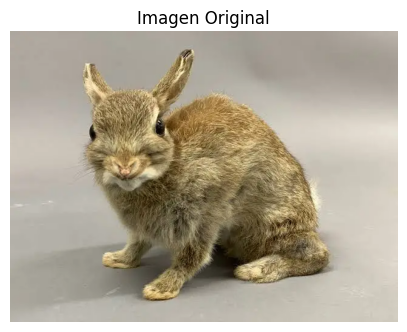

In [7]:
import numpy as np
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image

# 1. Cargar la imagen desde la URL
url = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRKyGHbHr6rKb_WLUc734gbjCBEcvtXe11kvh3Yxl-mq5TddPNN_7GHUBjkgDco4cASRyMZq8p8ceC1l0NQWNo4WSmSwnEDJnAmpg0eIGg&s=10"
response = requests.get(url)
img = Image.open(BytesIO(response.content))

# Mostrar la imagen original
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis('off')
plt.title("Imagen Original")
plt.show()

In [8]:
# 2. Preprocesar la imagen para VGG16 (224x224)
img_resized = img.resize((224, 224))
x = image.img_to_array(img_resized)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# 3. Cargar el modelo VGG16 preentrenado con ImageNet
model = VGG16(weights='imagenet')

# 4. Realizar la predicción
preds = model.predict(x)

# Decodificar y obtener los 3 mejores resultados
decoded_preds = decode_predictions(preds, top=3)[0]

# 5. Mostrar los resultados
print("\n--- Primeros 3 resultados de la predicción ---")
for i, (imagenet_id, label, score) in enumerate(decoded_preds):
    percentage = score * 100
    print(f"{i+1}. {label} ({percentage:.2f}%)")

# Imprimir el resultado más alto de forma destacada
best_label = decoded_preds[0][1]
best_percentage = decoded_preds[0][2] * 100
print(f"\nPredicción con el resultado más alto: {best_label} con un {best_percentage:.2f}% de probabilidad.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 770ms/step

--- Primeros 3 resultados de la predicción ---
1. wood_rabbit (22.50%)
2. lynx (20.21%)
3. hare (18.80%)

Predicción con el resultado más alto: wood_rabbit con un 22.50% de probabilidad.
